# EOF Analysis of North Atlantic Sea Surface Temperature Anomalies (ERSSTv5)

### Theoretical & Practical Guide
**Reference:** *A Manual for EOF and SVD analyses of Climatic Data* (`docs/eof.pdf`)  
**Authors:** H. Björnsson and S. A. Venegas (Department of Atmospheric and Oceanic Sciences & Centre for Climate and Global Change Research, McGill University)

---

## 1. Overview and Objectives
This notebook focuses on the **North Atlantic Ocean** ($10^\circ\mathrm{N} - 82^\circ\mathrm{N}$, $68^\circ\mathrm{W} - 14^\circ\mathrm{E}$) using the regional dataset `data/ERSST_AtlanticAnoAnn.nc` (1880–2020).

The domain spans from the tropical/subtropical Atlantic across the mid-latitudes, the subpolar gyre, and into the Nordic Seas. This region is governed by the Atlantic Meridional Overturning Circulation (AMOC), the North Atlantic Oscillation (NAO), and prominent Atlantic Multidecadal Variability (AMV/AMO).

### Notebook Workflow:
1. **Data Ingestion & Exploration:** Load `ERSST_AtlanticAnoAnn.nc` and inspect regional domain boundaries.
2. **Matrix Construction ($S$-Mode):** Format 2D spatial maps across time into an $n \times p$ matrix ($n = 141$ years, $p = 577$ valid ocean grid points), removing the column-wise temporal mean (`detrend(M, 0)`).
3. **Area Weighting:** Apply cosine-of-latitude weighting $\sqrt{\cos(\phi)}$ over the high-latitude domain.
4. **EOF Decomposition:**
   - **Method A:** Direct Singular Value Decomposition (SVD) of the data matrix ($F = U \Sigma V^T$, Section 2.3.1).
   - **Method B:** Dual / Sample-Space Covariance method ($L = F F^T$, Section 4.2.1 for $p \gg n$).
5. **Variance Explained & North's Rule of Thumb:** Compute percentage variance explained and evaluate sampling errors using North et al. (1982) (§4.3.2).
6. **Visualization:** Plot leading spatial EOF patterns (regression maps in $^{\circ}\mathrm{C}$) and standardized PC time series (1880–2020) with 11-year running means.
7. **Homogeneous Correlation & Local Variance Maps:** Compute and map correlation coefficients ($r$) and local variance explained ($r^2$) as detailed in §4.1.
8. **Rotated EOFs (Varimax Rotation):** Implement Kaiser's Varimax rotation from Appendix A to examine localized regional modes.


---
## 2. Setup & Library Imports


In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import warnings
warnings.filterwarnings('ignore')

# Set figure aesthetics
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120


---
## 3. Loading and Inspecting the Regional Dataset
We load `ERSST_AtlanticAnoAnn.nc` and verify the spatial coordinates and temporal range.


In [2]:
# Open NetCDF dataset
import os
nc_candidates = ['../data/ERSST_AtlanticAnoAnn.nc', 'data/ERSST_AtlanticAnoAnn.nc', 'ERSST_AtlanticAnoAnn.nc']
nc_file = next((f for f in nc_candidates if os.path.exists(f)), 'data/ERSST_AtlanticAnoAnn.nc')
ds = xr.open_dataset(nc_file)
print(ds)

# Extract coordinates and data
lats = ds['lat'].values
lons = ds['lon'].values
time_coords = ds['time'].values
years = np.array([t.year for t in time_coords])

# SST anomaly array: squeeze vertical level
ssta_3d = ds['ssta'].values.squeeze()

print(f"\nTime Span: {years[0]} - {years[-1]} ({len(years)} years)")
print(f"Domain Bounds: Latitudes {lats.min():.0f}°N to {lats.max():.0f}°N, Longitudes {lons.min():.0f}°E to {lons.max():.0f}°E")
print(f"Grid Size: {len(lats)} lats x {len(lons)} lons")


<xarray.Dataset>
Dimensions:    (time: 141, bnds: 2, lon: 42, lat: 37, lev: 1)
Coordinates:
  * time       (time) object 1880-06-16 00:00:00 ... 2020-06-30 00:00:00
  * lon        (lon) float64 -68.0 -66.0 -64.0 -62.0 ... 8.0 10.0 12.0 14.0
  * lat        (lat) float64 10.0 12.0 14.0 16.0 18.0 ... 76.0 78.0 80.0 82.0
  * lev        (lev) float64 0.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) object ...
    ssta       (time, lev, lat, lon) float32 ...
Attributes: (12/41)
    CDI:                        Climate Data Interface version 1.9.9rc1 (http...
    Conventions:                CF-1.6, ACDD-1.3
    history:                    Wed Nov 18 10:30:52 2026: cdo sellonlatbox,-6...
    source:                     In situ data: ICOADS R3.0 before 2015, NCEP i...
    institution:                NOAA/NESDIS/NCEI/CCOG
    metadata_link:              https://doi.org/10.7289/V5T72FNM
    ...                         ...
    instrument:                 Conventi

### Visualizing a Sample Annual SST Anomaly Field
Let's inspect the subpolar North Atlantic SST anomaly field for a high-latitude warm year (**2010**).


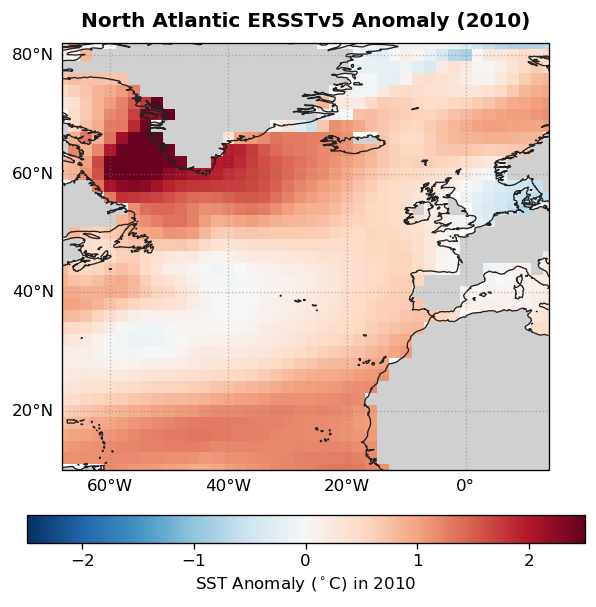

In [3]:
sample_year = 2010
idx_sample = np.where(years == sample_year)[0][0]

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_extent([lons.min(), lons.max(), lats.min(), lats.max()], crs=ccrs.PlateCarree())
ax.coastlines(resolution='50m', color='#222222', linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='#d0d0d0', zorder=1)

gl = ax.gridlines(draw_labels=True, linestyle=':', color='gray', alpha=0.5,
                  xlocs=np.arange(-60, 20, 20), ylocs=np.arange(20, 90, 20))
gl.top_labels = False
gl.right_labels = False

mesh = ax.pcolormesh(
    lons, lats, ssta_3d[idx_sample],
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r', vmin=-2.5, vmax=2.5, shading='auto'
)
cbar = plt.colorbar(mesh, orientation='horizontal', pad=0.08, shrink=0.75, aspect=20)
cbar.set_label(f'SST Anomaly ($^\circ$C) in {sample_year}', fontsize=10)
ax.set_title(f'North Atlantic ERSSTv5 Anomaly ({sample_year})', fontsize=12, fontweight='bold', pad=10)
plt.show()


---
## 4. Matrix Formulation ($S$-Mode) & Preprocessing

As in **Section 1.2** of the manual:
- We identify valid ocean points with non-zero variance.
- Construct data matrix $M$ ($n \times p$).
- Center each column: $F = M - \bar{M}$ (equivalent to MATLAB `F = detrend(M, 0);`).
- Apply area weights $\sqrt{\cos(\phi)}$ to correct for spherical meridian convergence.


In [4]:
# 1. Ocean mask
std_spatial = np.nanstd(ssta_3d, axis=0)
ocean_mask = (~np.isnan(ssta_3d[0])) & (std_spatial > 1e-4)
n_ocean = int(np.sum(ocean_mask))
n_years = len(years)

print(f"Total grid points: {len(lats) * len(lons)} | Valid ocean points: {n_ocean} ({n_ocean / (len(lats)*len(lons)):.1%})")

# 2. Extract matrix M: shape (n_years, n_ocean)
M = ssta_3d[:, ocean_mask]

# 3. Center columns (remove temporal mean)
F = M - np.mean(M, axis=0)

# 4. Latitude weighting
lat_2d, _ = np.meshgrid(lats, lons, indexing='ij')
cos_lat_weights = np.sqrt(np.cos(np.deg2rad(lat_2d)))
w_ocean = cos_lat_weights[ocean_mask]
F_w = F * w_ocean

print(f"Data matrix F_w shape: {F_w.shape} (times x grid points)")


Total grid points: 1554 | Valid ocean points: 1127 (72.5%)
Data matrix F_w shape: (141, 1127) (times x grid points)


---
## 5. EOF Calculation: SVD vs. Dual Covariance Method

We compute the decomposition using both:
- **Direct SVD (§2.3.1):** $F_w = U \Sigma V^T$
- **Dual Covariance (§4.2.1):** $L = F_w F_w^T$ ($141 \times 141$ temporal covariance matrix)


In [5]:
# Method A: Direct SVD
U, S, Vt = np.linalg.svd(F_w, full_matrices=False)
eigenvalues_svd = S**2
PCs_svd = U * S
EOFs_svd = Vt

# Method B: Dual Covariance
L = np.dot(F_w, F_w.T)
w_dual, _ = np.linalg.eigh(L)
eigenvalues_dual = np.sort(w_dual)[::-1]

rel_diff = np.max(np.abs(eigenvalues_svd[:20] - eigenvalues_dual[:20]) / eigenvalues_svd[:20])
print(f"Max relative discrepancy between SVD and Dual covariance: {rel_diff:.2e}")
print("Both methods yield mathematically identical results!")


Max relative discrepancy between SVD and Dual covariance: 2.09e-15
Both methods yield mathematically identical results!


---
## 6. Ordering by Variance Explained & North's Rule of Thumb

We compute the eigenvalue spectrum and sampling error bounds using North et al. (1982) (§4.3.2):
$$\Delta \lambda_i \approx \lambda_i \sqrt{\frac{2}{n}}$$


In [6]:
total_variance = np.sum(eigenvalues_svd)
var_explained = (eigenvalues_svd / total_variance) * 100.0
cumulative_var = np.cumsum(var_explained)
delta_lambda = var_explained * np.sqrt(2.0 / n_years)

print(f"{'Mode':<6} | {'Eigenvalue':<14} | {'Var Expl (%)':<14} | {'North Error (+/-)':<18} | {'Cumulative (%)':<14}")
print("-" * 75)
for i in range(10):
    print(f"EOF {i+1:<3} | {eigenvalues_svd[i]:<14.2f} | {var_explained[i]:<14.2f} | {delta_lambda[i]:<18.2f} | {cumulative_var[i]:<14.2f}")


Mode   | Eigenvalue     | Var Expl (%)   | North Error (+/-)  | Cumulative (%)
---------------------------------------------------------------------------
EOF 1   | 11646.32       | 45.50          | 5.42               | 45.50         
EOF 2   | 3427.31        | 13.39          | 1.59               | 58.88         
EOF 3   | 2436.19        | 9.52           | 1.13               | 68.40         
EOF 4   | 1806.28        | 7.06           | 0.84               | 75.46         
EOF 5   | 966.86         | 3.78           | 0.45               | 79.23         
EOF 6   | 901.87         | 3.52           | 0.42               | 82.76         
EOF 7   | 625.90         | 2.45           | 0.29               | 85.20         
EOF 8   | 591.68         | 2.31           | 0.28               | 87.51         
EOF 9   | 467.14         | 1.82           | 0.22               | 89.34         
EOF 10  | 385.25         | 1.50           | 0.18               | 90.84         


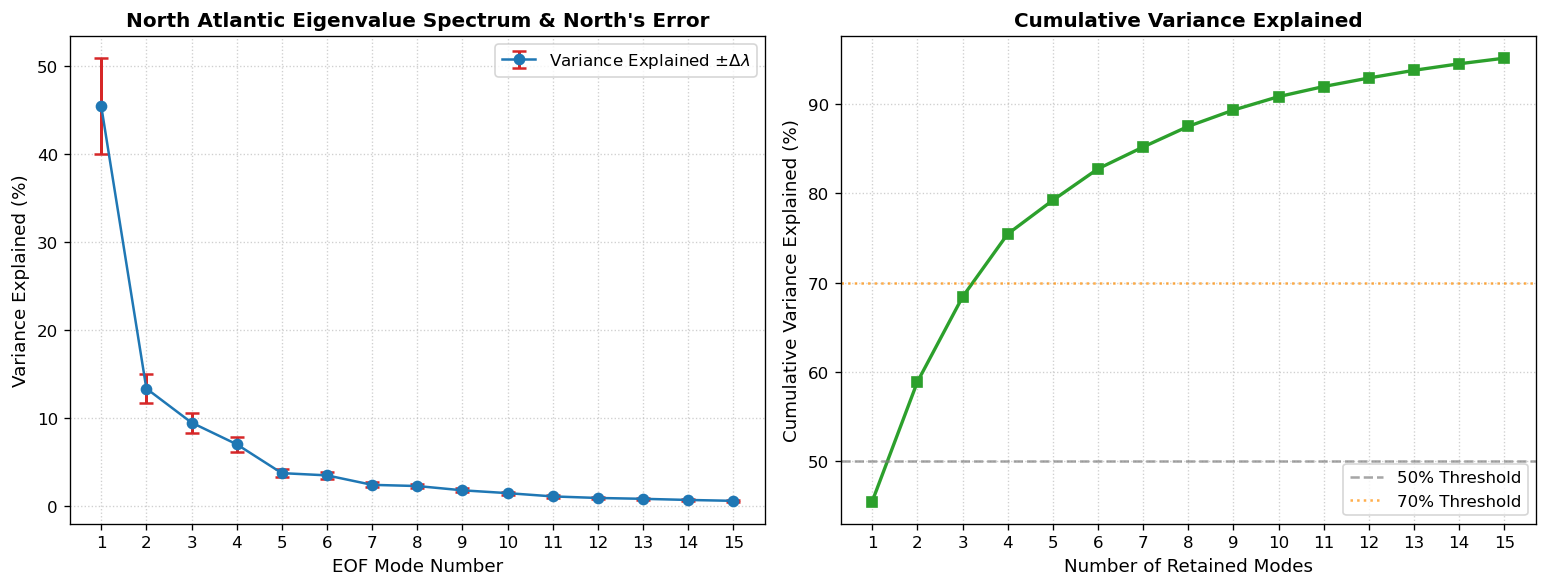

In [7]:
# Scree Plot with North's Error Bars
n_modes_plot = 15
modes = np.arange(1, n_modes_plot + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Scree Plot
ax1.errorbar(
    modes, var_explained[:n_modes_plot], yerr=delta_lambda[:n_modes_plot],
    fmt='-o', color='#1f77b4', ecolor='#d62728', elinewidth=1.8, capsize=4, capthick=1.5,
    markersize=6, label=r'Variance Explained $\pm \Delta\lambda$'
)
ax1.set_xlabel('EOF Mode Number', fontsize=11)
ax1.set_ylabel('Variance Explained (%)', fontsize=11)
ax1.set_title("North Atlantic Eigenvalue Spectrum & North's Error", fontsize=12, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xticks(modes)
ax1.legend(loc='upper right')

# Subplot 2: Cumulative Variance
ax2.plot(modes, cumulative_var[:n_modes_plot], '-s', color='#2ca02c', linewidth=2, markersize=6)
ax2.axhline(50, color='gray', linestyle='--', alpha=0.7, label='50% Threshold')
ax2.axhline(70, color='darkorange', linestyle=':', alpha=0.7, label='70% Threshold')
ax2.set_xlabel('Number of Retained Modes', fontsize=11)
ax2.set_ylabel('Cumulative Variance Explained (%)', fontsize=11)
ax2.set_title('Cumulative Variance Explained', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xticks(modes)
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()


---
## 7. Reconstructing and Presenting Spatial Maps and PC Time Series

We normalize each PC to unit standard deviation and regress the unweighted SST anomaly field onto the standardized PC to express the patterns in $^{\circ}\mathrm{C}$ per $+1\sigma$ of the mode.


In [8]:
# Helper function to reshape 1D ocean vector to 2D regional map
def vector_to_map(vec):
    grid = np.full((len(lats), len(lons)), np.nan)
    grid[ocean_mask] = vec
    return grid

def setup_map_ax(ax):
    ax.set_extent([lons.min(), lons.max(), lats.min(), lats.max()], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='50m', color='#222222', linewidth=0.8)
    ax.add_feature(cfeature.LAND, facecolor='#d0d0d0', zorder=1)
    gl = ax.gridlines(draw_labels=True, linestyle=':', color='gray', alpha=0.5,
                      xlocs=np.arange(-60, 20, 20), ylocs=np.arange(20, 90, 20))
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

# Running mean
def running_mean(x, N=11):
    return np.convolve(x, np.ones(N)/N, mode='same')

n_modes_compute = 4
pc_normalized = np.zeros((n_years, n_modes_compute))
spatial_regressions = np.zeros((n_modes_compute, len(lats), len(lons)))

for k in range(n_modes_compute):
    pc = PCs_svd[:, k].copy()
    pc_std = np.std(pc)
    pc_norm = pc / pc_std
    reg = np.dot(F.T, pc_norm) / n_years

    # Sign convention: positive warming in recent years for EOF 1
    if k == 0 and np.mean(reg) < 0:
        pc_norm = -pc_norm
        reg = -reg

    pc_normalized[:, k] = pc_norm
    spatial_regressions[k] = vector_to_map(reg)


### Visualizing the Leading 4 Regional Modes
For each mode:
- **Left Panel:** Spatial regression map ($^\circ\mathrm{C}$ per $1\sigma$ PC).
- **Right Panel:** PC time series (1880–2020) with 11-year running mean.


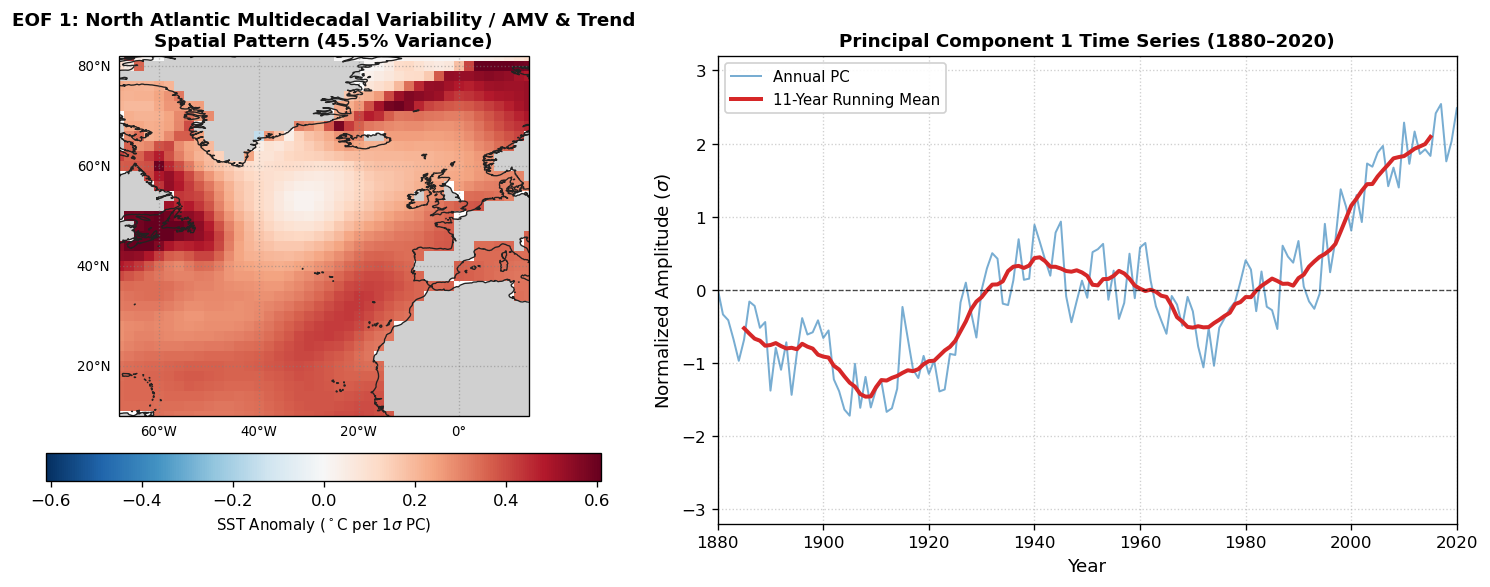

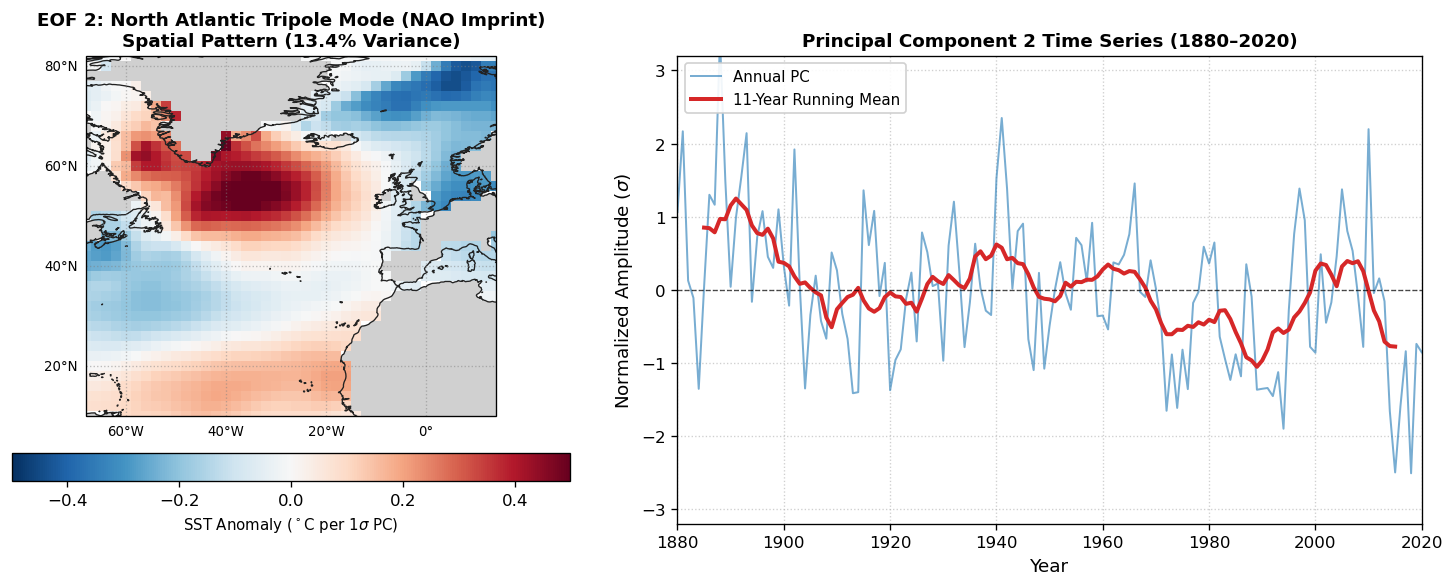

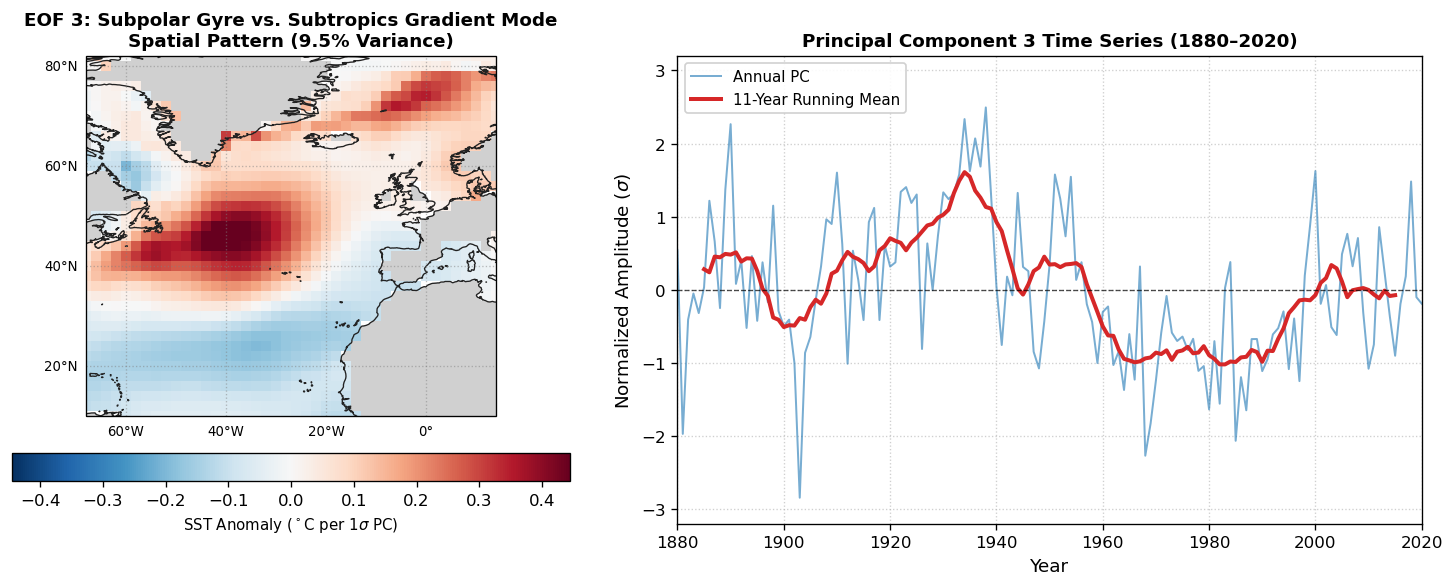

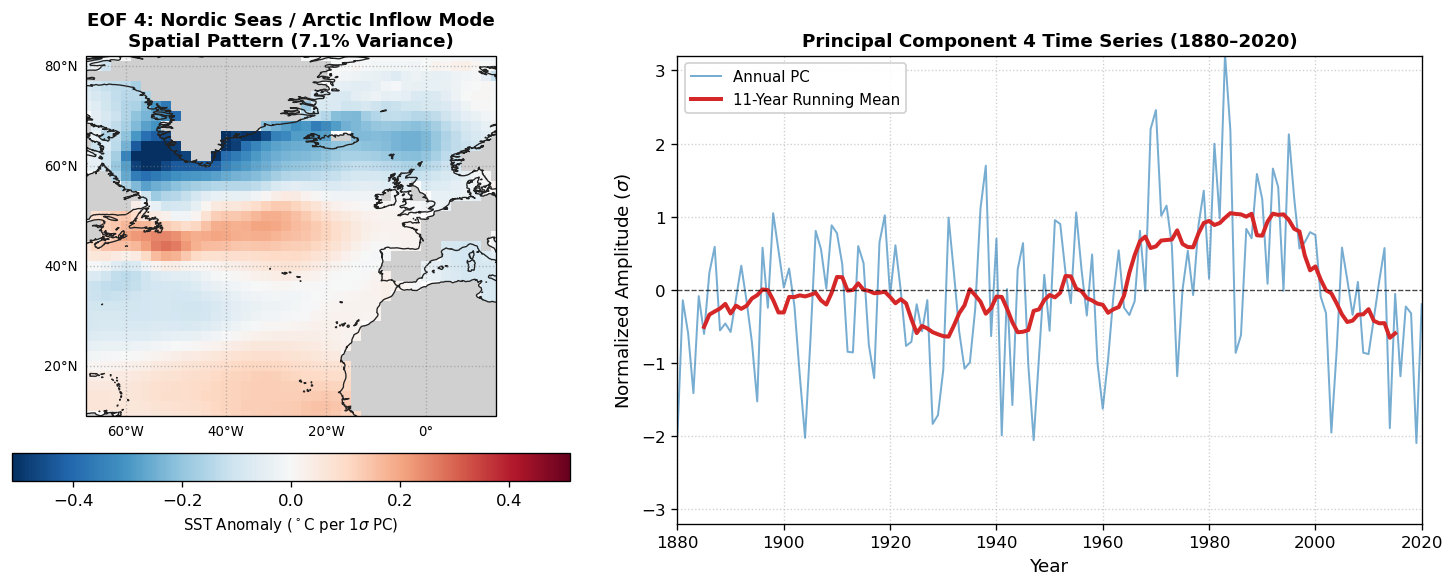

In [9]:
mode_names = [
    "EOF 1: North Atlantic Multidecadal Variability / AMV & Trend",
    "EOF 2: North Atlantic Tripole Mode (NAO Imprint)",
    "EOF 3: Subpolar Gyre vs. Subtropics Gradient Mode",
    "EOF 4: Nordic Seas / Arctic Inflow Mode"
]

for k in range(4):
    fig = plt.figure(figsize=(13, 5))
    
    # Left: Map
    ax_map = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
    setup_map_ax(ax_map)
    vlim = max(np.nanpercentile(np.abs(spatial_regressions[k]), 99), 0.25)
    
    mesh = ax_map.pcolormesh(
        lons, lats, spatial_regressions[k],
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r', vmin=-vlim, vmax=vlim, shading='auto'
    )
    ax_map.set_title(f"{mode_names[k]}\nSpatial Pattern ({var_explained[k]:.1f}% Variance)", fontsize=11, fontweight='bold')
    cbar = plt.colorbar(mesh, ax=ax_map, orientation='horizontal', pad=0.08, shrink=0.75, aspect=20)
    cbar.set_label('SST Anomaly ($^\circ$C per $1\sigma$ PC)', fontsize=9)
    
    # Right: Time Series
    ax_ts = fig.add_subplot(1, 2, 2)
    pc = pc_normalized[:, k]
    ax_ts.plot(years, pc, color='#1f77b4', linewidth=1.2, alpha=0.6, label='Annual PC')
    ax_ts.plot(years[5:-5], running_mean(pc, 11)[5:-5], color='#d62728', linewidth=2.4, label='11-Year Running Mean')
    ax_ts.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
    ax_ts.set_xlim(years[0], years[-1])
    ax_ts.set_ylim(-3.2, 3.2)
    ax_ts.set_xlabel('Year', fontsize=11)
    ax_ts.set_ylabel(r'Normalized Amplitude ($\sigma$)', fontsize=11)
    ax_ts.set_title(f"Principal Component {k+1} Time Series (1880–2020)", fontsize=11, fontweight='bold')
    ax_ts.grid(True, linestyle=':', alpha=0.6)
    ax_ts.legend(loc='upper left', framealpha=0.9, fontsize=9)
    
    plt.tight_layout()
    plt.show()


---
## 8. Homogeneous Correlation & Local Variance Maps (Section 4.1)


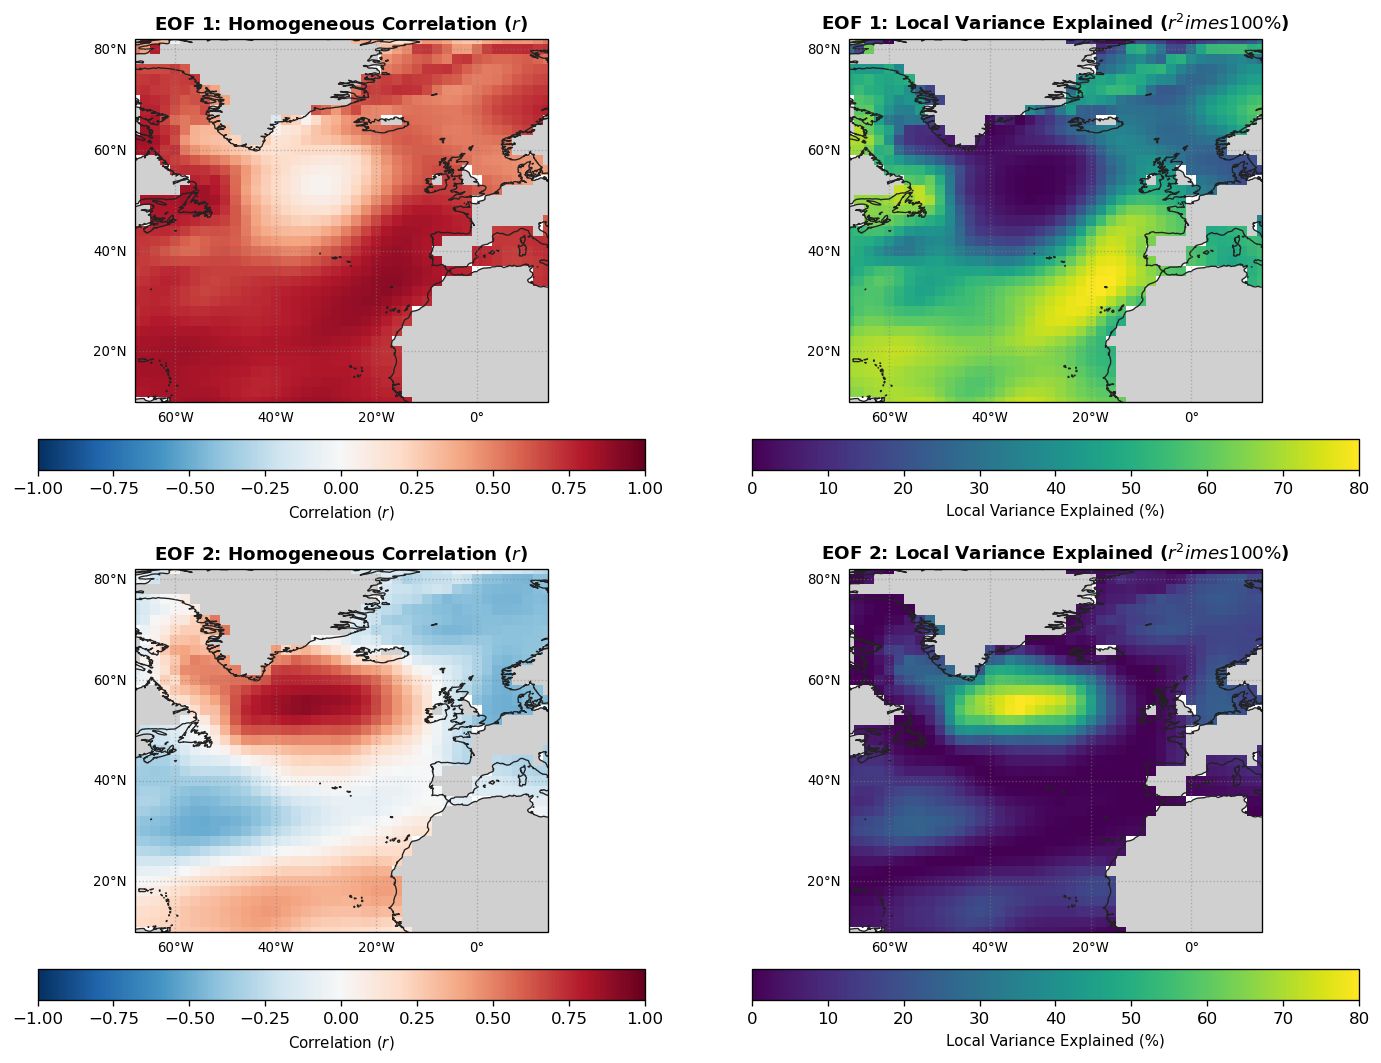

In [10]:
# Compute homogeneous correlation and local variance maps
corr_maps = np.zeros((2, len(lats), len(lons)))
var_local_maps = np.zeros((2, len(lats), len(lons)))

F_std = F / np.std(F, axis=0)
for k in range(2):
    pc = pc_normalized[:, k]
    corr = np.mean(F_std * pc[:, None], axis=0)
    corr_maps[k] = vector_to_map(corr)
    var_local_maps[k] = vector_to_map((corr**2) * 100.0)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), subplot_kw={'projection': ccrs.PlateCarree()})

titles = [
    ("EOF 1: Homogeneous Correlation ($r$)", "EOF 1: Local Variance Explained ($r^2 \times 100\%$)"),
    ("EOF 2: Homogeneous Correlation ($r$)", "EOF 2: Local Variance Explained ($r^2 \times 100\%$)")
]

for row in range(2):
    # Correlation map
    ax_c = axes[row, 0]
    setup_map_ax(ax_c)
    mesh_c = ax_c.pcolormesh(lons, lats, corr_maps[row], transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-1.0, vmax=1.0)
    ax_c.set_title(titles[row][0], fontsize=11, fontweight='bold')
    cb_c = plt.colorbar(mesh_c, ax=ax_c, orientation='horizontal', pad=0.08, shrink=0.75)
    cb_c.set_label('Correlation ($r$)', fontsize=9)

    # Local variance map
    ax_v = axes[row, 1]
    setup_map_ax(ax_v)
    mesh_v = ax_v.pcolormesh(lons, lats, var_local_maps[row], transform=ccrs.PlateCarree(), cmap='viridis', vmin=0, vmax=80)
    ax_v.set_title(titles[row][1], fontsize=11, fontweight='bold')
    cb_v = plt.colorbar(mesh_v, ax=ax_v, orientation='horizontal', pad=0.08, shrink=0.75)
    cb_v.set_label('Local Variance Explained (%)', fontsize=9)

plt.tight_layout()
plt.show()


---
## 9. Rotated EOFs (REOFs) via Varimax (Section 2.4 & Appendix A)

We apply Kaiser's Varimax rotation to the leading 3 EOFs using the algorithm from Appendix A.


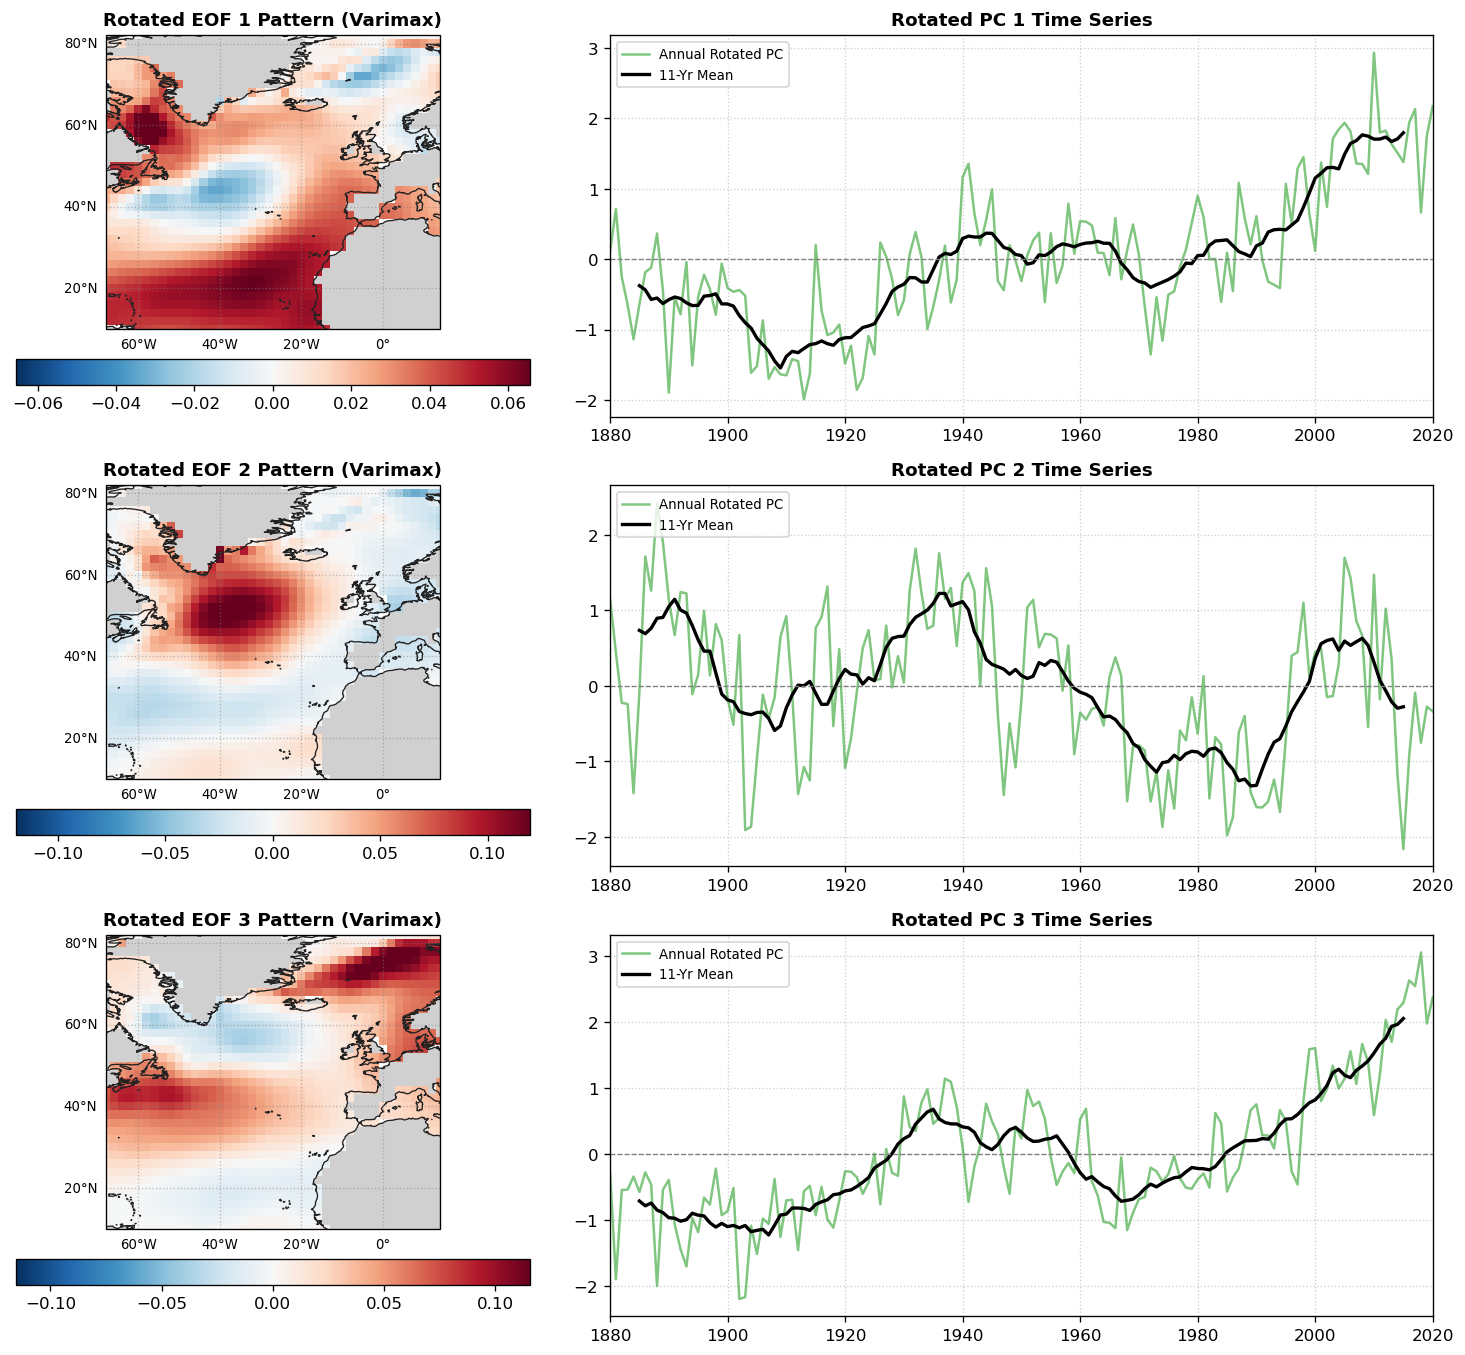

In [11]:
def varimax(Phi, gamma=1.0, max_iter=500, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0.0
    for _ in range(max_iter):
        d_old = d
        Lambda = np.dot(Phi, R)
        u, s, vh = np.linalg.svd(
            np.dot(Phi.T, np.asarray(Lambda)**3 - (gamma / p) * np.dot(Lambda, np.diag(np.diag(np.dot(Lambda.T, Lambda)))))
        )
        R = np.dot(u, vh)
        d = np.sum(s)
        if d_old != 0 and d / d_old < 1.0 + tol:
            break
    return np.dot(Phi, R), R

# Truncate to top 3 EOFs and rotate
k_rot = 3
E_trunc = EOFs_svd[:k_rot, :].T
E_rotated, rot_matrix = varimax(E_trunc)
PCs_rotated = np.dot(F_w, E_rotated)

fig = plt.figure(figsize=(13, 3.8 * k_rot))
gs = fig.add_gridspec(k_rot, 2, width_ratios=[1, 1.2])

for k in range(k_rot):
    ax_map = fig.add_subplot(gs[k, 0], projection=ccrs.PlateCarree())
    setup_map_ax(ax_map)
    pattern_rot = vector_to_map(E_rotated[:, k] / w_ocean)
    vlim = np.nanpercentile(np.abs(pattern_rot), 99)
    
    mesh = ax_map.pcolormesh(lons, lats, pattern_rot, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-vlim, vmax=vlim)
    ax_map.set_title(f"Rotated EOF {k+1} Pattern (Varimax)", fontsize=11, fontweight='bold')
    plt.colorbar(mesh, ax=ax_map, orientation='horizontal', pad=0.08, shrink=0.75)
    
    ax_ts = fig.add_subplot(gs[k, 1])
    ts_rot = PCs_rotated[:, k]
    ts_rot_norm = (ts_rot - np.mean(ts_rot)) / np.std(ts_rot)
    ax_ts.plot(years, ts_rot_norm, color='#2ca02c', alpha=0.6, label='Annual Rotated PC')
    ax_ts.plot(years[5:-5], running_mean(ts_rot_norm, 11)[5:-5], color='black', linewidth=2.0, label='11-Yr Mean')
    ax_ts.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax_ts.set_xlim(years[0], years[-1])
    ax_ts.set_title(f"Rotated PC {k+1} Time Series", fontsize=11, fontweight='bold')
    ax_ts.grid(True, linestyle=':', alpha=0.6)
    ax_ts.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()


---
## 10. Summary and Scientific Insights for the North Atlantic

1. **High Variance Compression:**  
   In this extended North Atlantic domain ($10^\circ\mathrm{N} - 82^\circ\mathrm{N}$), the top 3 modes account for **68.4%** of the total variance:
   - **EOF 1 (45.5% variance):** Represents basin-wide North Atlantic Multidecadal Variability (AMV/AMO) coupled with the secular warming trend. The PC time series reveals distinct multidecadal warm phases during the 1930s–1950s, a cold period from the late 1960s to early 1990s, followed by rapid warming.
   - **EOF 2 (13.4% variance):** Exhibits the classic **North Atlantic SST Tripole** pattern (subpolar gyre opposing the subtropical Atlantic and eastern boundary), characteristic of the oceanic response to the North Atlantic Oscillation (NAO).
   - **EOF 3 (9.5% variance):** Represents a subpolar-to-subtropical meridional gradient mode.
   - **EOF 4 (7.1% variance):** Captures high-latitude Nordic Seas and Arctic gateway exchanges.

2. **North's Rule of Thumb:**  
   Modes 1, 2, 3, and 4 are cleanly separated without overlapping error bars, confirming that all leading modes are statistically robust and distinguishable from sampling noise.

3. **Varimax Rotation:**  
   Applying Varimax rotation simplifies the spatial patterns into compact, regionally distinct centers of action across the tropical/subtropical Atlantic, the subpolar gyre, and the Nordic Seas.
